---
title: "Hamiltonian Mechanics — Level 2"
short_title: "11 Hamiltonian Mechanics"
numbering:
  heading_2: true
  equation: true
---

# Hamiltonian Mechanics

:::{seealso} Math for this topic
- [M7: Legendre transforms, phase portraits and hyperbolic functions](../math/07-legendre-phase-hyperbolic.ipynb)
- [M3: Multivariable calculus](../math/03-multivariable-calculus.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (not in Tipler & Mosca) | Start at Level 2 |
| **2** | **Taylor, ch. 13** | **Legendre transform, Hamilton's equations, phase space, Liouville's theorem** |
| 3 | Goldstein, ch. 8–10 | Canonical transformations, Poisson brackets, Hamilton–Jacobi theory |

The new skill at this level: replacing n second-order equations with 2n first-order ones on phase space, where geometry becomes the tool

Math for this topic: M7 (Legendre transform, phase portraits) and M3 (partial derivatives).
:::

Builds on the Lagrangian notes. Exercises have separate hint and answer dropdowns. A small sympy helper below builds H and Hamilton's equations from any Lagrangian.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## From Lagrangian to Hamiltonian

Lagrangian mechanics uses positions and velocities, $(q, \dot q)$. Hamiltonian mechanics uses positions and **momenta**, $(q, p)$, with

$$
p_i = \frac{\partial\mathcal{L}}{\partial\dot q_i} .
$$

Trading $\dot q_i$ for its slope variable $p_i$ is exactly a Legendre transform (M7). Define the **Hamiltonian**

$$
\mathcal{H}(q, p, t) = \sum_ip_i\dot q_i - \mathcal{L}(q, \dot q, t) ,
$$ (eq-hamiltonian)

with every $\dot q_i$ rewritten in terms of the $p$'s and $q$'s. This is the quantity $h$ from the Lagrangian notes, now expressed in new variables. For the usual case (coordinates that do not depend on time, $U$ independent of velocities), it is the total energy, $\mathcal{H} = T + U$.

### Hamilton's equations

The Legendre-transform rules from M7 give two of the equations at once: $\partial\mathcal{H}/\partial p_i = \dot q_i$, and the passive variables flip sign, $\partial\mathcal{H}/\partial q_i = -\partial\mathcal{L}/\partial q_i$. Lagrange's equations say $\partial\mathcal{L}/\partial q_i = \dot p_i$. So

$$
\dot q_i = \frac{\partial\mathcal{H}}{\partial p_i}, \qquad \dot p_i = -\frac{\partial\mathcal{H}}{\partial q_i} .
$$ (eq-hamilton)

Instead of $n$ second-order equations, there are $2n$ first-order ones, with an almost perfect symmetry between $q$ and $p$.

### Energy and ignorable coordinates

Along a solution, the chain rule and {eq}`eq-hamilton` give

$$
\frac{d\mathcal{H}}{dt} = \sum_i\left(\frac{\partial\mathcal{H}}{\partial q_i}\dot q_i + \frac{\partial\mathcal{H}}{\partial p_i}\dot p_i\right) + \frac{\partial\mathcal{H}}{\partial t} = \frac{\partial\mathcal{H}}{\partial t} .
$$

If $\mathcal{H}$ has no explicit time dependence, it is conserved. And if $\mathcal{H}$ does not contain some $q_i$, then $\dot p_i = 0$: the same cyclic-coordinate rule as before, but now that $p_i$ is simply a constant in $\mathcal{H}$, and the problem genuinely loses a degree of freedom.

:::{important} The recipe
1. Write $\mathcal{L}$ and find each $p_i = \partial\mathcal{L}/\partial\dot q_i$.
2. Solve for the $\dot q_i$ in terms of the $p$'s.
3. Form $\mathcal{H} = \sum p_i\dot q_i - \mathcal{L}$ in terms of $q$ and $p$ (or, for natural systems, just write $T + U$ in terms of $q$ and $p$).
4. Apply {eq}`eq-hamilton`.
:::

In [2]:
# A helper that does the recipe for any Lagrangian
t = sp.symbols("t")

def hamiltonian(L, qs):
    qdots = [q.diff(t) for q in qs]
    ps = sp.symbols(f"p_1:{len(qs) + 1}")
    sol = sp.solve([sp.Eq(p, L.diff(qd)) for p, qd in zip(ps, qdots)], qdots, dict=True)[0]
    H = sp.simplify((sum(p * qd for p, qd in zip(ps, qdots)) - L).subs(sol))
    qsyms = sp.symbols(f"q_1:{len(qs) + 1}")
    H = H.subs(dict(zip(qs, qsyms)))
    eqs = [(f"d{q}/dt", sp.diff(H, p)) for q, p in zip(qsyms, ps)] + \
          [(f"d{p}/dt", -sp.diff(H, q)) for q, p in zip(qsyms, ps)]
    return H, eqs

# Particle in a central potential U(r), polar coordinates (q1 = r, q2 = phi)
m = sp.symbols("m", positive=True)
r, ph = sp.Function("r")(t), sp.Function("phi")(t)
U = sp.Function("U")
L = sp.Rational(1, 2) * m * (r.diff(t)**2 + r**2 * ph.diff(t)**2) - U(r)
H, eqs = hamiltonian(L, [r, ph])
print("H =", H)
for name, rhs in eqs:
    print(f"{name:8s} =", sp.simplify(rhs))

H = U(q_1) + p_1**2/(2*m) + p_2**2/(2*m*q_1**2)
dq_1/dt  = p_1/m
dq_2/dt  = p_2/(m*q_1**2)
dp_1/dt  = -Derivative(U(q_1), q_1) + p_2**2/(m*q_1**3)
dp_2/dt  = 0


In the output, $q_2 = \phi$ does not appear in $\mathcal{H}$, so $\dot p_2 = 0$: the angular momentum $p_\phi = mr^2\dot\phi$ is constant. The radial equations then describe a one-dimensional problem with the centrifugal term $p_2^2/(2mr^2)$ built in, the effective potential from the angular momentum notes, arrived at automatically.

### Exercises

1. Find $\mathcal{H}$ and Hamilton's equations for a mass on a spring, $\mathcal{L} = \tfrac12m\dot x^2 - \tfrac12kx^2$, and show they reproduce $m\ddot x = -kx$.
2. Find $\mathcal{H}$ for the Atwood machine of the Lagrangian notes, $\mathcal{L} = \tfrac12(m_1 + m_2)\dot x^2 + (m_1 - m_2)gx$.
3. For the bead on a spinning hoop, $\mathcal{L} = \tfrac12mR^2(\dot\theta^2 + \omega^2\sin^2\theta) + mgR\cos\theta$. Find $\mathcal{H}$ and explain why it is conserved but is not $T + U$.

:::{dropdown} Hints
1. $p = m\dot x$.
2. $p = (m_1 + m_2)\dot x$.
3. $p = mR^2\dot\theta$. Compare $\mathcal{H}$ with $T = \tfrac12mR^2(\dot\theta^2 + \omega^2\sin^2\theta)$.
:::

:::{dropdown} Answers
1. $\mathcal{H} = p^2/2m + \tfrac12kx^2$; $\dot x = p/m$ and $\dot p = -kx$ combine to $m\ddot x = -kx$.
2. $\mathcal{H} = \dfrac{p^2}{2(m_1 + m_2)} - (m_1 - m_2)gx$.
3. $\mathcal{H} = \dfrac{p^2}{2mR^2} - \tfrac12mR^2\omega^2\sin^2\theta - mgR\cos\theta$. It has no explicit $t$, so it is conserved, but the $\omega^2$ term enters with a minus sign, unlike in $T + U$. The motor turning the hoop does work, so $T + U$ itself changes.
:::

## Phase Space

The state of a system with $n$ degrees of freedom is a point $(q_1, \dots, q_n, p_1, \dots, p_n)$ in a $2n$-dimensional **phase space**. Hamilton's equations give a velocity at every point, so the motion is a flow in phase space, and the M7 phase-portrait tools apply directly.

Because the equations are first order, exactly one trajectory passes through each point: **phase-space trajectories never cross**. (Paths in ordinary space cross all the time, because the same position can be reached with different momenta.)

For one degree of freedom with conserved $\mathcal{H}$, the trajectories are simply the level curves $\mathcal{H}(q, p) = E$:

- A harmonic oscillator, $\mathcal{H} = p^2/2m + \tfrac12kx^2$, traces ellipses. The area enclosed by the ellipse at energy $E$ is $2\pi E/\omega$.
- A pendulum traces closed curves (swinging) inside its separatrix and open curves (rotating) outside, exactly the M7 portrait with $\dot\phi$ replaced by $p_\phi = mL^2\dot\phi$.

:::{note} A glimpse of quantum mechanics
The phase-space area $\oint p\,dq$ of an oscillator orbit is $2\pi E/\omega$. Requiring it to be a whole number of Planck constants $h$ gives $E = n\hbar\omega$, the old (pre-1925) quantum rule, off from the exact answer only by the zero-point energy $\tfrac12\hbar\omega$. Phase-space area turns out to be the natural measure of "how many states" a system has, which is why it is central to statistical mechanics.
:::

## Liouville's Theorem

Follow not one initial state but a whole region of them, a blob in phase space, and let each point move by Hamilton's equations. The blob moves and changes shape, but:

:::{prf:theorem} Liouville's theorem
:label: thm-liouville

Under Hamiltonian flow, the volume of any region of phase space is constant in time.
:::

:::{prf:proof} Proof sketch
:class: dropdown
A flow with velocity field $\vec{u}$ preserves volume when $\nabla\cdot\vec{u} = 0$ (the divergence theorem, from the vector calculus notes). In phase space the velocity is $(\dot q_i, \dot p_i)$, so

$$
\nabla\cdot\vec{u} = \sum_i\left(\frac{\partial\dot q_i}{\partial q_i} + \frac{\partial\dot p_i}{\partial p_i}\right) = \sum_i\left(\frac{\partial^2\mathcal{H}}{\partial q_i\partial p_i} - \frac{\partial^2\mathcal{H}}{\partial p_i\partial q_i}\right) = 0 .
$$

Phase-space flow behaves like an incompressible fluid.
:::

Friction breaks the theorem: damped motion pulls phase-space regions toward an attractor and shrinks their area, which the next figure shows.

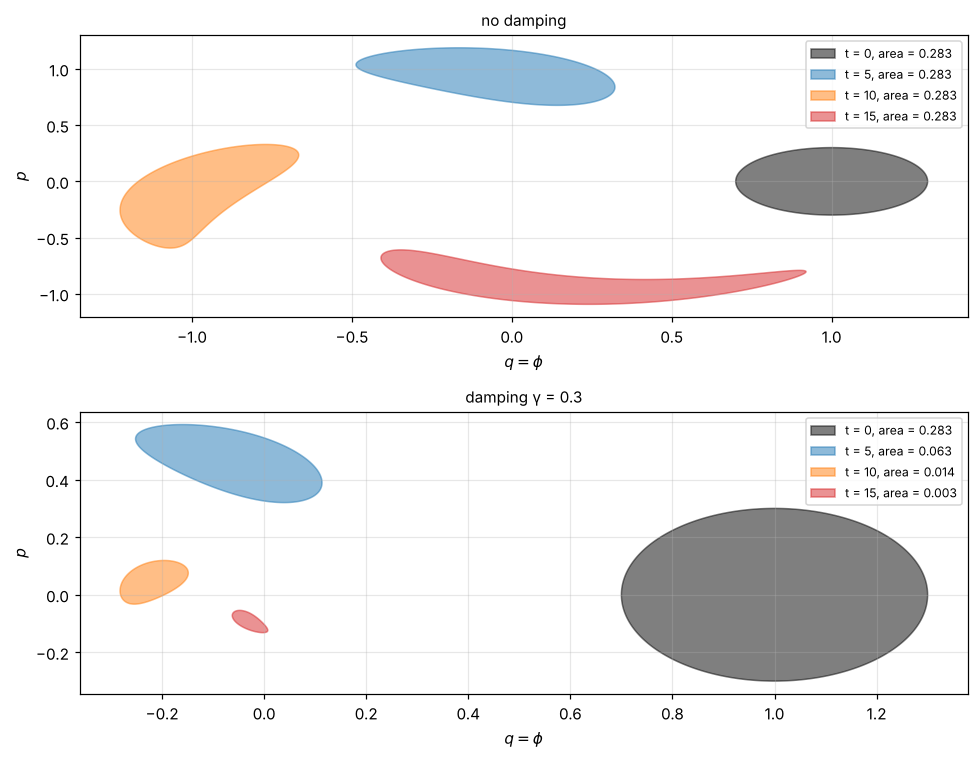

In [3]:
#| label: fig-liouville
#| caption: A small disk of initial states for the pendulum (black), evolved in time. Without damping (top) the region is stretched into a long filament but its area, computed from the boundary, stays the same. With damping (bottom) the area shrinks as states spiral toward rest.
def evolve(gamma, T, n_pts=600):
    th = np.linspace(0, 2 * np.pi, n_pts, endpoint=False)
    q0, p0 = 1.0 + 0.3 * np.cos(th), 0.0 + 0.3 * np.sin(th)
    rhs = lambda t, y: np.concatenate([y[n_pts:], -np.sin(y[:n_pts]) - gamma * y[n_pts:]])
    sol = solve_ivp(rhs, (0, T), np.concatenate([q0, p0]), t_eval=[0, T / 3, 2 * T / 3, T], rtol=1e-10, atol=1e-12)
    return sol.y[:n_pts], sol.y[n_pts:], sol.t

def area(q, p):   # shoelace formula for a closed polygon
    return 0.5 * abs(np.dot(q, np.roll(p, -1)) - np.dot(p, np.roll(q, -1)))

fig, axes = plt.subplots(2, 1, figsize=(9, 7))
for ax, gamma in zip(axes, [0.0, 0.3]):
    Q, P, ts = evolve(gamma, 15.0)
    for k, c in enumerate(["k", "tab:blue", "tab:orange", "tab:red"]):
        ax.fill(Q[:, k], P[:, k], color=c, alpha=0.5, label=f"t = {ts[k]:.0f}, area = {area(Q[:, k], P[:, k]):.3f}")
    ax.set_xlabel(r"$q = \phi$"); ax.set_ylabel(r"$p$")
    ax.set_title("no damping" if gamma == 0 else f"damping γ = {gamma}", fontsize=10)
    ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## Why Bother with the Hamiltonian?

For solving a typical mechanics problem, Lagrange's equations are usually just as quick. The Hamiltonian formulation earns its place elsewhere:

- **Statistical mechanics** counts states by phase-space volume, and Liouville's theorem is what makes that count consistent over time.
- **Quantum mechanics** is built on $\mathcal{H}$: the Hamiltonian becomes the operator in Schrödinger's equation, and the Poisson-bracket structure of Hamilton's equations (Level 3) turns into commutators.
- **Perturbation theory and chaos** (celestial mechanics, accelerator design, plasma confinement) are studied with canonical transformations that keep Hamilton's equations' form, the Level 3 rung of this topic.

### Exercises

1. Show that the area enclosed by an oscillator's phase-space ellipse at energy $E$ is $2\pi E/\omega$.
2. For a particle in a uniform gravitational field, $\mathcal{H} = p^2/2m + mgx$. Draw the phase-space trajectories and check Liouville's theorem for a small rectangle of initial conditions over a time $t$.
3. Show directly that the damped oscillator $\dot x = p/m$, $\dot p = -kx - (b/m)p$ has phase-space divergence $-b/m$, so areas shrink as $e^{-bt/m}$.

:::{dropdown} Hints
1. The ellipse has semi-axes $\sqrt{2E/k}$ and $\sqrt{2mE}$.
2. $p(t) = p_0 - mgt$ and $x(t) = x_0 + p_0t/m - \tfrac12gt^2$. How does a rectangle in $(x_0, p_0)$ map?
3. Compute $\partial\dot x/\partial x + \partial\dot p/\partial p$.
:::

:::{dropdown} Answers
1. Area $= \pi\sqrt{2E/k}\sqrt{2mE} = 2\pi E\sqrt{m/k} = 2\pi E/\omega$.
2. Trajectories are parabolas $x = x_* - p^2/(2m^2g)$. The map is a shear plus a shift: $p$ shifts uniformly, and $x$ shifts by an amount linear in $p_0$. A shear preserves area.
3. $0 + (-b/m) = -b/m$, so by the divergence theorem the area obeys $\dot A = -(b/m)A$.
:::

## Summary

- $\mathcal{H}(q, p, t) = \sum p\dot q - \mathcal{L}$ is the Legendre transform of $\mathcal{L}$ in the velocities; for natural systems it is $T + U$.
- Hamilton's equations, $\dot q = \partial\mathcal{H}/\partial p$ and $\dot p = -\partial\mathcal{H}/\partial q$, are $2n$ first-order ODEs.
- $d\mathcal{H}/dt = \partial\mathcal{H}/\partial t$; ignorable coordinates give constant momenta that drop out of the problem.
- Motion is a flow on phase space whose trajectories never cross; for one degree of freedom they are level curves of $\mathcal{H}$.
- Liouville's theorem: Hamiltonian flow preserves phase-space volume. Friction shrinks it.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.